In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [2]:
R, L, C = sp.symbols(" R L C")

zeta = R / (2 * L)
opl1 = sp.diff(zeta, R)
opl2 = sp.diff(zeta, L)
display(opl1, opl2)

omega = 1 / sp.sqrt(L * C)
opl3 = sp.diff(omega, L)
opl4 = sp.diff(omega, C)
display(opl3, opl4)

1/(2*L)

-R/(2*L**2)

-1/(2*L*sqrt(C*L))

-1/(2*C*sqrt(C*L))

In [5]:
#OPGAVE 1 & 2

In [7]:
#OPGAVE 3
syst_fout = 10e3
L = 2.2e-3
C = 15e-9
R = 100

resfreq = [0.3*100e3, 0.2*100e3, 0.3*100e3, 0.3*100e3, 0.4*100e3]

gemiddelde = np.mean(resfreq) #schatter

stddev = 0
for i in resfreq:
    stddev += (i - gemiddelde)**2 #eveneens schatter, vandaar deze formule

dev = sp.sqrt(1/4 * stddev)
display(dev) #<10k, dsyst

verwachte_waarde = sp.N(1 / (2 * sp.pi * sp.sqrt(L*C))) # [Hz], ervanuitgaande dat nul fout door fabrikant
display(verwachte_waarde)

7071.06781186548

27705.3194271996

<ErrorbarContainer object of 3 artists>

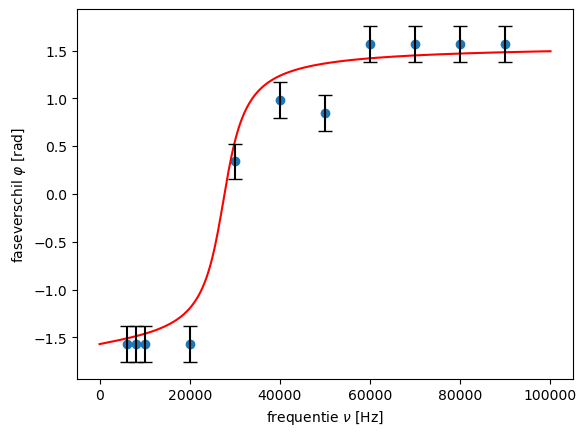

In [91]:
#OPGAVE 4

freq = [6e3, 8e3, 10e3, 20e3, 30e3, 40e3, 50e3, 60e3, 70e3, 80e3, 90e3] # [Hz]
A = [0.2, 0.2, 0.4, 1, 0.4, 1, 0.6, 0.4, 0.4, 0.4, 0.2] # [mV]
B = [0.2, 0.2, 0.4, 1, 1.2, 1.2, 0.8, 0.4, 0.4, 0.4, 0.2] # [mV]

phi = []

#absolute waardes faseverschil
for i in range(len(A)):
    phi.append((sp.asin(A[i]/B[i])))

#teken
for i in range(4):
    phi[i] = -phi[i]

#foutenbalken

a, b = sp.symbols("a b")
phi_func = sp.asin(a/b)

fout_a = 0.2 # [mV]
fout_b = 0.2 # [mV]

fout_phi = sp.sqrt((sp.diff(phi_func, a))**2 * fout_a**2 + (sp.diff(phi_func, b))**2 * fout_b**2)

fout_phi_lijst = []
for i in range(len(A)):
    if A[i] == B[i]:
        fout_phi_lijst.append(fout_phi.subs([(a, A[i]), (b, B[i] + 1e-9)]))
    else:
        fout_phi_lijst.append(fout_phi.subs([(a, A[i]), (b, B[i])]))

#theoretische waarde

X = np.linspace(0.001, 100e3, 500)
phi_functie = np.arctan((2 * np.pi * X*L - 1/(2 * np.pi * X * C))/R)

#grafiek

fig, ax = plt.subplots()
ax.plot(freq, phi, 'o')
plt.xlabel(r'frequentie $\nu$ [Hz]')
plt.ylabel(r'faseverschil $\varphi$ [rad]')
ax.plot(X, phi_functie, color = 'red')

fout_phi_lijst_logisch = [fout_a, fout_a, fout_a, fout_a, fout_phi_lijst[4], fout_phi_lijst[5], fout_phi_lijst[6], fout_a, fout_a, fout_a, fout_a,]

#wiskundig juiste fout, fysisch niet → systematische fout

ax.errorbar(freq, phi, yerr = fout_phi_lijst_logisch[4], fmt = 'none', capsize = 5, color = 'black')



In [15]:
display(fout_phi_lijst)
display(fout_phi_lijst_logisch)

[14142.1356391438,
 14142.1356391438,
 9999.99988186505,
 6324.55504920191,
 0.186338998124983,
 0.392479813545110,
 0.472455591261534,
 9999.99988186505,
 9999.99988186505,
 9999.99988186505,
 14142.1356391438]

[0.2,
 0.2,
 0.2,
 0.2,
 0.186338998124983,
 0.392479813545110,
 0.472455591261534,
 0.2,
 0.2,
 0.2,
 0.2]

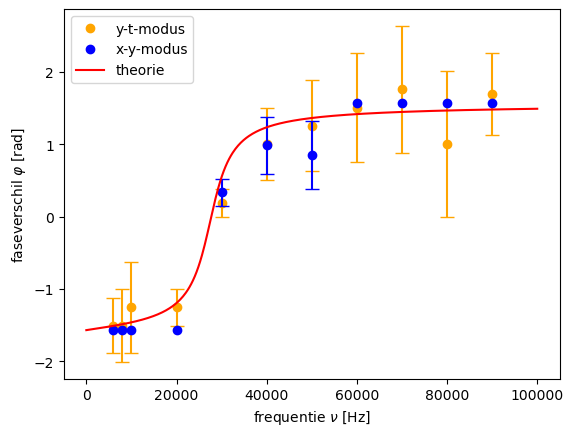

In [93]:
#OPDRACHT 5

#berekenen
t = [-40, -30, -20, -10, 1, 4, 4, 4, 4, 2, 3] # [µs]
berekend_faseverschil = [] #zelfde periode want zelfde frequentie

for i in range(len(t)):
    berekend_faseverschil.append(2 * np.pi * t[i] * 1e-6 * freq[i])

#fouten
fouten_t = [10, 10, 10, 2, 1, 2, 2, 2, 2, 2, 1] # [µs]

fout_phi_berekend = []
for i in range(len(fouten_t)):
    fout_phi_berekend.append(2*np.pi*freq[i] * fouten_t[i]*1e-6)


#figuur
fig, ax = plt.subplots()

ax.plot(freq, berekend_faseverschil, 'o', color = 'orange', label = "y-t-modus")
ax.errorbar(freq, berekend_faseverschil, yerr = fout_phi_berekend,fmt = 'none', capsize = 5, color = 'orange')

ax.plot(freq, phi, 'o', color = 'blue', label = "x-y-modus")
ax.errorbar(freq[4], phi[4], yerr = fout_phi_lijst_logisch[4], color = 'blue', capsize = 5, fmt = 'none')
ax.errorbar(freq[5], phi[5], yerr = fout_phi_lijst_logisch[5], color = 'blue', capsize = 5, fmt = 'none')
ax.errorbar(freq[6], phi[6], yerr = fout_phi_lijst_logisch[6], color = 'blue', capsize = 5, fmt = 'none')

ax.plot(X, phi_functie, color = 'red', label = "theorie")

plt.xlabel(r'frequentie $\nu$ [Hz]')
plt.ylabel(r'faseverschil $\varphi$ [rad]')

ax.legend()

plt.savefig("oscilloscoop.png")